In [1]:
# Move the root directory to the system path 
import sys
from pathlib import Path

root_dir = Path().resolve().parent
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from src.utils import load_splits, load_config
from src.predict import load_model, image_caption

In [3]:
# Load config
config, config_dir = load_config()

In [4]:
# Load the model and other necessary components
model, vocab, transform, device = load_model(config, config_dir)

In [5]:
# Load the test split JSON file
test_data = load_splits(config_dir / config["paths"]["test_json"])

image_names = list(test_data.keys())
# First 5 image names from test set
image_names[:5]

['1007129816.jpg',
 '1009434119.jpg',
 '101362133.jpg',
 '102617084.jpg',
 '10287332.jpg']

In [6]:
image_dir = Path(config_dir / config["paths"]["images"])

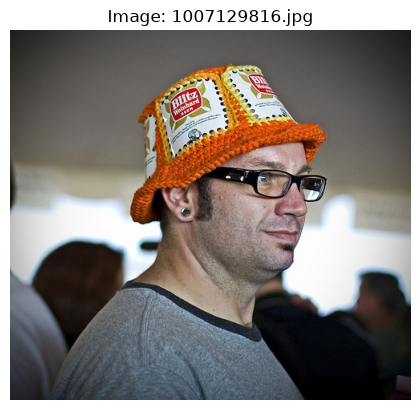

Caption: A man wearing a hat and a hat is holding a camera .


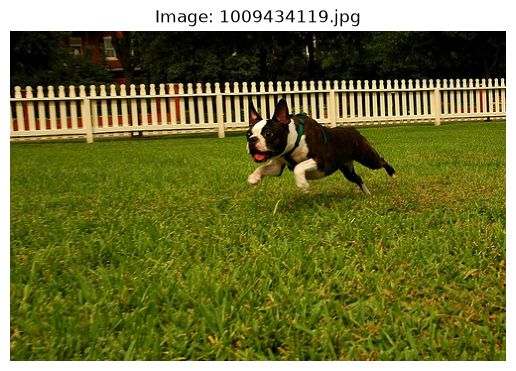

Caption: A black and white dog is running through a grassy field .


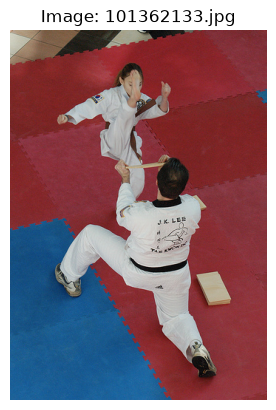

Caption: Two young girls are practicing martial arts in a gym .


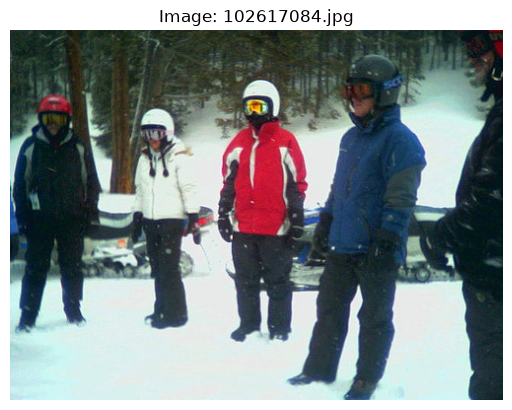

Caption: A group of people are standing in the snow .


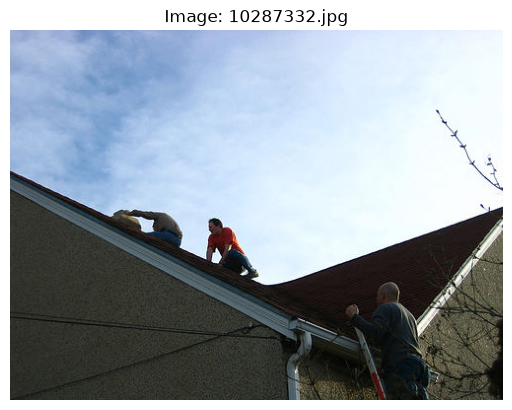

Caption: Two men are working on a roof .


In [7]:
# Display the first 5 images and their captions
for image_name in image_names[:5]:
    image_path = str(image_dir / image_name)
    image = Image.open(image_path).convert("RGB")
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Image: {image_name}")
    plt.show()
    caption_lst = image_caption(image_path, model, vocab, transform, device, method="beam")
    caption = " ".join(caption_lst)
    print(f"Caption: {caption.capitalize()}")